# Project 1: Advanced EDA & Feature Engineering
**DecodeLabs | Data Science | Batch 2026**

**Goal:** turn the raw order dataset into a clean, machine-learning-ready dataset.

**Core requirements (from the project brief)**
1. Handle missing data with statistical imputation (Mean / Median / KNN)
2. Identify and neutralize outliers using Z-scores or the IQR
3. Engineer at least 3 new predictive features from existing columns

**How the notebook follows the brief's Input → Process → Output blueprint**

| Module | What happens here | Brief concept |
|---|---|---|
| 0 | Load, profile and explore the data | Starting point |
| 1 - INPUT | Missing values, integrity checks, outliers | "Securing input fidelity" |
| 2 - PROCESS | Vectorized features, one-hot encoding, collinearity removal | "The vectorized computation engine" |
| 3 - OUTPUT | Schema validation, verification, export | "Structural contracts" |

**Assumptions (written down so a reviewer can challenge them)**
- **A1.** A blank `CouponCode` means "no coupon used", so it is kept as its own category instead of being imputed.
- **A2.** The dataset has no target column. For the collinearity step I define `is_failed` = order was Cancelled or Returned. *(To be confirmed with the instructor.)*
- **A3.** Section 1.4 runs an imputation **simulation on a separate copy**. It never changes the real data. *(To be confirmed with the instructor.)*

*Run the notebook top to bottom (Kernel → Restart & Run All).*

## Module 0: Load, profile and explore

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
RANDOM_SEED = 42

In [3]:
# The path is relative to this notebook: the data/ folder sits next to it.
raw_data = pd.read_excel('data/Dataset for Data Analytics.xlsx')   # untouched reference copy
df = raw_data.copy()                                                # all changes happen on this copy
raw_data.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [4]:
# Profile of the raw data (the "before" evidence)
raw_data.info()
print("\nRows:", len(raw_data))
print("\nMissing values per column:")
print(raw_data.isnull().sum())
print("\nDuplicate OrderIDs:", raw_data['OrderID'].duplicated().sum())
print("Fully duplicated rows:", raw_data.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   OrderID          1200 non-null   object        
 1   Date             1200 non-null   datetime64[ns]
 2   CustomerID       1200 non-null   object        
 3   Product          1200 non-null   object        
 4   Quantity         1200 non-null   int64         
 5   UnitPrice        1200 non-null   float64       
 6   ShippingAddress  1200 non-null   object        
 7   PaymentMethod    1200 non-null   object        
 8   OrderStatus      1200 non-null   object        
 9   TrackingNumber   1200 non-null   object        
 10  ItemsInCart      1200 non-null   int64         
 11  CouponCode       891 non-null    object        
 12  ReferralSource   1200 non-null   object        
 13  TotalPrice       1200 non-null   float64       
dtypes: datetime64[ns](1), float64(2), int64(

In [5]:
num_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
cat_cols = ["Product", "PaymentMethod", "OrderStatus", "CouponCode", "ReferralSource"]

display(raw_data[num_cols].describe().round(2))
print("Skewness:")
print(raw_data[num_cols].skew().round(2))

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.00,1200.00,1200.00,1200.00
mean,2.95,356.41,5.48,1053.97
std,1.41,197.18,2.28,819.86
min,1.00,11.39,1.00,11.39
25%,2.00,186.06,4.00,410.52
50%,3.00,364.21,5.00,823.62
75%,4.00,521.57,7.00,1578.48
max,5.00,699.93,10.00,3456.40


Skewness:
Quantity       0.03
UnitPrice     -0.03
ItemsInCart    0.00
TotalPrice     0.89
dtype: float64


In [6]:
for c in cat_cols:
    print(f"\n{c}")
    print(raw_data[c].value_counts(dropna=False))


Product
Product
Printer    181
Tablet     179
Chair      178
Laptop     173
Desk       170
Monitor    163
Phone      156
Name: count, dtype: int64

PaymentMethod
PaymentMethod
Online         258
Cash           246
Credit Card    234
Debit Card     232
Gift Card      230
Name: count, dtype: int64

OrderStatus
OrderStatus
Cancelled    250
Returned     247
Pending      237
Shipped      235
Delivered    231
Name: count, dtype: int64

CouponCode
CouponCode
FREESHIP    313
NaN         309
WINTER15    292
SAVE10      286
Name: count, dtype: int64

ReferralSource
ReferralSource
Instagram    259
Email        250
Google       241
Facebook     228
Referral     222
Name: count, dtype: int64


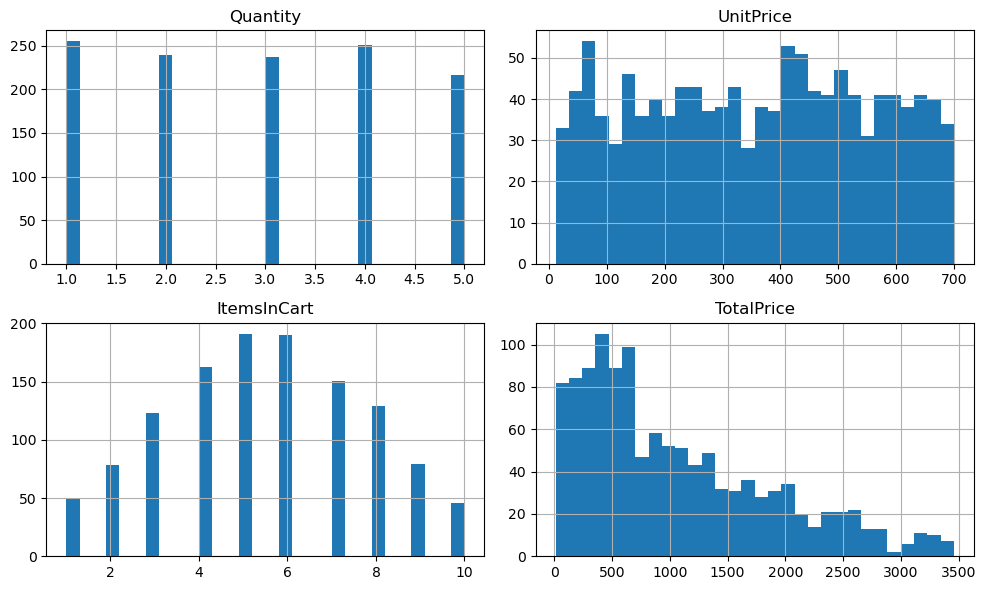

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.00,0.01,0.65,0.62
UnitPrice,0.01,1.00,0.00,0.72
ItemsInCart,0.65,0.00,1.00,0.39
TotalPrice,0.62,0.72,0.39,1.00


In [7]:
raw_data[num_cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

display(raw_data[num_cols].corr().round(2))

**EDA notes**
- `TotalPrice` is the product of two roughly uniform columns, so it is right-skewed. The skew comes from how it is built, not from bad data.
- `TotalPrice` correlates with `UnitPrice` and `Quantity` because it is calculated from them. That matters again in the collinearity step.
- Category counts are close to evenly split, so no category is rare enough to need grouping.

## Module 1 - INPUT: securing data fidelity

### 1.1 Missing-value audit (Missing Data Decision Matrix)
The brief's matrix picks a strategy from the share of missing values in each column:
`< 5%` drop rows, `5% - 20%` statistical imputation, `> 20%` KNN.

In [8]:
miss_pct = (raw_data.isnull().mean() * 100).round(2)
audit = pd.DataFrame({"missing_pct": miss_pct})
audit["matrix_rule"] = np.select(
    [audit["missing_pct"] == 0, audit["missing_pct"] < 5, audit["missing_pct"] <= 20],
    ["none missing", "drop rows (<5%)", "statistical imputation (5-20%)"],
    default="KNN (>20%)",
)
audit[audit["missing_pct"] > 0]

,missing_pct,matrix_rule
CouponCode,25.75,KNN (>20%)


**Decision for `CouponCode` (assumption A1).** The matrix would say KNN for this column (25.75% missing). I deliberately do **not** follow it here:
- `CouponCode` is categorical, and its three coupon values and the blanks each make up about a quarter of the rows. That pattern fits a blank that means "no coupon", not a lost value.
- Imputing would invent coupons for the 309 orders that did not use one, which adds synthetic bias.

So the blanks become an explicit `"No Coupon"` category. This also avoids the sample-size loss of deleting 25.75% of the data.

### 1.2 Cleaning steps


In [9]:
# Step 1: blank coupons mean "no coupon used"
df['CouponCode'] = df['CouponCode'].fillna('No Coupon')

# Step 2: make sure Date is a real datetime (kept as datetime for feature engineering later)
df['Date'] = pd.to_datetime(df['Date'])
assert df['Date'].notna().all(), "Some dates could not be parsed"

# Step 3: enforce 2-decimal precision on money columns
df[['UnitPrice', 'TotalPrice']] = df[['UnitPrice', 'TotalPrice']].round(2)

# Step 4: trim whitespace on text columns
for c in df.select_dtypes(include=['object', 'string']).columns:
    df[c] = df[c].str.strip()

# Integrity checks
assert df['OrderID'].is_unique, "Duplicate OrderIDs found"
assert df.isnull().sum().sum() == 0, "Missing values remain"
assert ((df['Quantity'] * df['UnitPrice']).round(2) == df['TotalPrice']).all(), "TotalPrice mismatch"
print("All cleaning checks passed. Rows:", len(df))

All cleaning checks passed. Rows: 1200


In [10]:
print(df.isnull().sum())
print(df['CouponCode'].value_counts())

OrderID            0
Date               0
CustomerID         0
Product            0
Quantity           0
UnitPrice          0
ShippingAddress    0
PaymentMethod      0
OrderStatus        0
TrackingNumber     0
ItemsInCart        0
CouponCode         0
ReferralSource     0
TotalPrice         0
dtype: int64
CouponCode
FREESHIP     313
No Coupon    309
WINTER15     292
SAVE10       286
Name: count, dtype: int64


### 1.3 Integrity audit: export, verify, and check repeated CustomerIDs
The dates are exported in ISO 8601 (`YYYY-MM-DD`), and the checks then run on the **exported file** reloaded as text, so they prove what is actually delivered.

In [11]:
df.to_csv('data/cleaned_data.csv', index=False, date_format='%Y-%m-%d')

check = pd.read_csv('data/cleaned_data.csv', dtype=str)
assert check['Date'].str.match(r'^\d{4}-\d{2}-\d{2}$').all()
assert check['OrderID'].is_unique
print("Duplicate OrderIDs:", check['OrderID'].duplicated().sum())
print("Invalid date formats:", (~check['Date'].str.match(r'^\d{4}-\d{2}-\d{2}$')).sum())
print("Verified on the exported file")

Duplicate OrderIDs: 0
Invalid date formats: 0
Verified on the exported file


In [12]:
counts = df['CustomerID'].value_counts()
repeat_ids = counts[counts > 1].index
repeat_rows = df[df['CustomerID'].isin(repeat_ids)]

print("CustomerIDs appearing more than once:", len(repeat_ids))
print("Hidden duplicate rows (ignoring OrderID):",
      repeat_rows.drop(columns='OrderID').duplicated().sum())
print("Repeated IDs with identical date:",
      (repeat_rows.groupby('CustomerID')['Date'].nunique() == 1).sum())
print("Repeated IDs with identical tracking number:",
      (repeat_rows.groupby('CustomerID')['TrackingNumber'].nunique() == 1).sum())
print("Repeated IDs with identical shipping address:",
      (repeat_rows.groupby('CustomerID')['ShippingAddress'].nunique() == 1).sum())

CustomerIDs appearing more than once: 11
Hidden duplicate rows (ignoring OrderID): 0
Repeated IDs with identical date: 0
Repeated IDs with identical tracking number: 0
Repeated IDs with identical shipping address: 0


**Finding.** Every repeated CustomerID has different dates, tracking numbers and addresses, so none are duplicate records and all rows are kept.

### 1.4 Imputation demonstration (simulation on a separate copy)
**Assumption A3: pending instructor confirmation. This section never touches `df`.**

No numeric column has missing values, so there is nothing real to impute. To show how the three methods behave, I hide 10% of `UnitPrice` at random in a throwaway copy, fill the gaps with each method, and compare against the **true** values I hid.

- Mean and median fill every gap with one number.
- KNN looks at the most similar rows (using the other numeric columns) and averages their values. Features are scaled first because KNN works on distances and `TotalPrice` is on a much larger scale.
- `TotalPrice` is calculated from `UnitPrice`, so it is very informative here. I also run KNN **without** `TotalPrice` to see how much of KNN's advantage comes from that.

In [13]:
rng = np.random.default_rng(RANDOM_SEED)
sim_true = df[num_cols].copy()                 # complete data = ground truth
mask = np.zeros(len(sim_true), dtype=bool)
mask[rng.choice(len(sim_true), size=int(0.10 * len(sim_true)), replace=False)] = True   # exactly 10%, chosen at random
sim = sim_true.copy()
sim.loc[mask, "UnitPrice"] = np.nan
print(f"Hidden UnitPrice values: {mask.sum()} of {len(sim)} ({mask.mean():.1%})")

true_vals = sim_true.loc[mask, "UnitPrice"]

def knn_impute(frame, cols, k=5):
    scaler = StandardScaler()
    scaled = scaler.fit_transform(frame[cols])
    filled = KNNImputer(n_neighbors=k).fit_transform(scaled)
    return pd.DataFrame(scaler.inverse_transform(filled), columns=cols, index=frame.index)["UnitPrice"]

imputed = {
    "Imputation using Mean":   sim["UnitPrice"].fillna(sim["UnitPrice"].mean()),
    "Imputation using Median": sim["UnitPrice"].fillna(sim["UnitPrice"].median()),
    "Imputation using KNN (all numeric cols)": knn_impute(sim, num_cols),
    "Imputation using KNN (without TotalPrice)": knn_impute(sim, ["Quantity", "UnitPrice", "ItemsInCart"]),
}

results = pd.DataFrame({
    name: {
        "RMSE on hidden values": float(np.sqrt(((s[mask] - true_vals) ** 2).mean())),
        "Std of full column": float(s.std()),
    }
    for name, s in imputed.items()
}).T.round(2)
print("True std of UnitPrice:", round(sim_true["UnitPrice"].std(), 2))
results

Hidden UnitPrice values: 120 of 1200 (10.0%)
True std of UnitPrice: 197.18


,RMSE on hidden values,Std of full column
Imputation using Mean,190.30,187.76
Imputation using Median,190.45,187.78
Imputation using KNN (all numeric cols),21.93,196.53
Imputation using KNN (without TotalPrice),223.88,189.76


**How to read this table**
- **RMSE** is the typical size of the error on the hidden values (lower is better).
- **Std of full column** shows whether a method keeps the natural spread of the data. A std well below the true std means the method squeezed the distribution toward its center. Mean and median imputation do this.
- KNN can only be as good as the information the other columns hold about the missing one. Compare the two KNN rows to see this.

### 1.5 Outlier detection (IQR and Z-score)
- **IQR rule:** values outside `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.
- **Z-score rule:** values with `|z| > 3`.

In [13]:
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
z = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()

outlier_report = pd.DataFrame({
    "lower_bound": lower.round(2),
    "upper_bound": upper.round(2),
    "iqr_outliers": ((df[num_cols] < lower) | (df[num_cols] > upper)).sum(),
    "z_outliers (|z|>3)": (z.abs() > 3).sum(),
    "max_abs_z": z.abs().max().round(2),
})
outlier_report

,lower_bound,upper_bound,iqr_outliers,z_outliers (|z|>3),max_abs_z
Quantity,-1.00,7.00,0,0,1.46
UnitPrice,-317.20,1024.83,0,0,1.75
ItemsInCart,-0.50,11.50,0,0,1.98
TotalPrice,-1341.41,3330.41,8,0,2.93


In [14]:
flagged = df["TotalPrice"] > upper["TotalPrice"]
print("Rows flagged by IQR in TotalPrice:", int(flagged.sum()))
df.loc[flagged, ["OrderID", "Product", "Quantity", "UnitPrice", "TotalPrice"]]

Rows flagged by IQR in TotalPrice: 8


,OrderID,Product,Quantity,UnitPrice,TotalPrice
107,ORD200107,Printer,5,670.75,3353.75
326,ORD200326,Laptop,5,670.48,3352.40
328,ORD200328,Tablet,5,674.04,3370.20
469,ORD200469,Chair,5,676.98,3384.90
632,ORD200632,Laptop,5,678.16,3390.80
789,ORD200789,Tablet,5,691.28,3456.40
1065,ORD201065,Printer,5,666.80,3334.00
1122,ORD201122,Monitor,5,678.19,3390.95


**Decision.** Only `TotalPrice` has IQR outliers, and the Z-score rule flags none (the largest |z| is below 3). The flagged rows are **valid** orders (a high quantity of an expensive product), not data-entry errors.

Following the brief's winsorization guidance, I **cap instead of deleting** rows with `np.clip`, so no records are lost. The capped values go into a **new column** (`TotalPrice_capped`), and the original `TotalPrice` is kept so that `TotalPrice = Quantity x UnitPrice` still holds in the data.

Values capped: 8
Rows before / after: 1200 / 1200


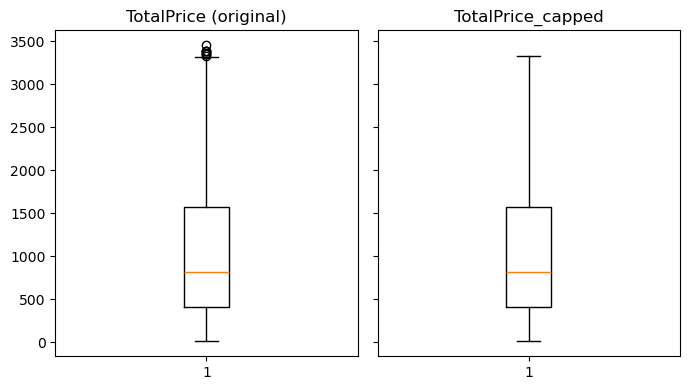

In [15]:
df["TotalPrice_capped"] = np.clip(df["TotalPrice"], lower["TotalPrice"], upper["TotalPrice"])

print("Values capped:", int((df["TotalPrice"] != df["TotalPrice_capped"]).sum()))
print("Rows before / after:", len(raw_data), "/", len(df))

fig, ax = plt.subplots(1, 2, figsize=(7, 4), sharey=True)
ax[0].boxplot(df["TotalPrice"])
ax[0].set_title("TotalPrice (original)")
ax[1].boxplot(df["TotalPrice_capped"])
ax[1].set_title("TotalPrice_capped")
plt.tight_layout()
plt.show()

## Module 2 - PROCESS: the vectorized engine
The brief asks for vectorized operations instead of row-by-row loops, so every feature below is a whole-column pandas/NumPy operation.

### 2.1 Feature engineering (5 new features)
| Feature | Built from | Why it might help |
|---|---|---|
| `used_coupon` | `CouponCode` | Discount use can change how likely an order is to complete |
| `other_items_in_cart` | `ItemsInCart`, `Quantity` | Separates a big basket from a big quantity of one product |
| `order_month` | `Date` | Captures seasonality |
| `is_weekend` | `Date` | Captures weekday vs weekend behavior |
| `price_tier` | `UnitPrice` | Groups prices into quartile bands (Low / Mid / High / Premium) |

In [16]:
df["used_coupon"] = (df["CouponCode"] != "No Coupon").astype("int64")
df["other_items_in_cart"] = (df["ItemsInCart"] - df["Quantity"]).astype("int64")
df["order_month"] = df["Date"].dt.month.astype("int64")
df["is_weekend"] = (df["Date"].dt.dayofweek >= 5).astype("int64")
df["price_tier"] = pd.qcut(df["UnitPrice"], 4, labels=["Low", "Mid", "High", "Premium"]).astype(str)

assert (df["other_items_in_cart"] >= 0).all(), "ItemsInCart is smaller than Quantity somewhere"

new_features = ["used_coupon", "other_items_in_cart", "order_month", "is_weekend", "price_tier"]
df[new_features].head()

,used_coupon,other_items_in_cart,order_month,is_weekend,price_tier
0,1,2,1,0,Premium
1,1,1,8,0,Low
2,1,3,2,0,Premium
3,1,4,10,1,Mid
4,1,4,5,0,Premium


### Target variable (assumption A2: pending instructor confirmation)
The dataset has no label, so I define `is_failed = 1` when the order was **Cancelled or Returned**. `OrderStatus` is excluded from the feature matrix so the target cannot leak into the features.


In [17]:
df["is_failed"] = df["OrderStatus"].isin(["Cancelled", "Returned"]).astype("int64")
print(df["is_failed"].value_counts(normalize=True).round(3))

is_failed
0    0.586
1    0.414
Name: proportion, dtype: float64


### 2.2 One-hot encoding
Label encoding would give nominal categories a fake order (for example Tokyo = 3x London). One-hot encoding avoids that by giving each category its own 0/1 column. I use `drop_first=True` so one category per feature is the baseline, which avoids the "dummy variable trap" (perfectly collinear dummy columns).

**Columns excluded from the feature matrix**
- `OrderID`, `CustomerID`, `TrackingNumber`: identifiers carry no predictive meaning.
- `ShippingAddress`: see the check below.
- `Date`: replaced by `order_month` and `is_weekend`.
- `OrderStatus`: the source of the target, so excluding it prevents leakage.

In [18]:
# Why ShippingAddress is excluded: the street name never varies
print(df["ShippingAddress"].str.replace(r"^\d+\s*", "", regex=True).unique())

['Main St']


In [19]:
id_like = ["OrderID", "CustomerID", "TrackingNumber", "ShippingAddress", "Date", "OrderStatus"]
categorical = ["Product", "PaymentMethod", "ReferralSource", "CouponCode", "price_tier"]

y = df["is_failed"]
X = pd.get_dummies(
    df.drop(columns=id_like + ["is_failed"]),
    columns=categorical,
    drop_first=True,
    dtype=int,
)
print("Feature matrix shape before collinearity removal:", X.shape)
X.head()

Feature matrix shape before collinearity removal: (1200, 29)


,Quantity,UnitPrice,ItemsInCart,TotalPrice,TotalPrice_capped,used_coupon,other_items_in_cart,order_month,is_weekend,Product_Desk,Product_Laptop,Product_Monitor,Product_Phone,Product_Printer,Product_Tablet,PaymentMethod_Credit Card,PaymentMethod_Debit Card,PaymentMethod_Gift Card,PaymentMethod_Online,ReferralSource_Facebook,ReferralSource_Google,ReferralSource_Instagram,ReferralSource_Referral,CouponCode_No Coupon,CouponCode_SAVE10,CouponCode_WINTER15,price_tier_Low,price_tier_Mid,price_tier_Premium
0,5,570.62,7,2853.10,2853.10,1,2,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,1
1,2,151.35,3,302.70,302.70,1,1,8,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,1,0,1,0,0
2,5,550.68,8,2753.40,2753.40,1,3,2,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1
3,1,273.19,5,273.19,273.19,1,4,10,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,1,0
4,4,626.01,8,2504.04,2504.04,1,4,5,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1


### 2.3 Collinearity eradication
Highly correlated predictors make regression coefficients unstable. The brief's algorithm:
1. Build the **absolute** correlation matrix
2. Keep only the **upper triangle** (so each pair appears once)
3. Find pairs with correlation **> 0.80**
4. For each pair, compare each feature's correlation with the **target** and drop the **weaker** one

(The loop below runs over the flagged *pairs*, not over data rows.)

In [20]:
THRESHOLD = 0.80

corr_abs = X.corr().abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape, dtype=bool), k=1))
pairs = upper_tri.stack()
pairs = pairs[pairs > THRESHOLD].sort_values(ascending=False)
print(f"Pairs with |correlation| > {THRESHOLD}: {len(pairs)}")
pairs

Pairs with |correlation| > 0.8: 2


used_coupon  CouponCode_No Coupon    1.000000
TotalPrice   TotalPrice_capped       0.999983
dtype: float64

In [21]:
target_corr = X.corrwith(y).abs()

to_drop, drop_log = set(), []
for (a, b), r in pairs.items():
    if a in to_drop or b in to_drop:
        continue                                   # one side already removed
    weaker = a if target_corr[a] < target_corr[b] else b
    kept = b if weaker == a else a
    to_drop.add(weaker)
    drop_log.append({
        "pair": f"{a}  <->  {b}",
        "pair_corr": round(r, 3),
        "dropped": weaker,
        "kept": kept,
        "corr_with_target (dropped / kept)": f"{target_corr[weaker]:.4f} / {target_corr[kept]:.4f}",
    })

drop_log = pd.DataFrame(drop_log)
X_final = X.drop(columns=sorted(to_drop))
print("Columns dropped:", sorted(to_drop))
print("Shape before / after:", X.shape, "/", X_final.shape)
drop_log

Columns dropped: ['CouponCode_No Coupon', 'TotalPrice']
Shape before / after: (1200, 29) / (1200, 27)


,pair,pair_corr,dropped,kept,corr_with_target (dropped / kept)
0,used_coupon <-> CouponCode_No Coupon,1.0,CouponCode_No Coupon,used_coupon,0.0233 / 0.0233
1,TotalPrice <-> TotalPrice_capped,1.0,TotalPrice,TotalPrice_capped,0.0086 / 0.0086


**Reading the result.** Both flagged pairs are collinear by construction. `used_coupon` is the exact mirror of the `CouponCode_No Coupon` dummy (correlation 1.0), and `TotalPrice_capped` is a copy of `TotalPrice` with only a few values clipped (correlation about 0.99998). A feature and its mirror carry the same information and have almost identical correlation with the target, so which one is dropped does not change what a model can learn. The original `TotalPrice` is only left out of the model matrix; it is still in `engineered_data.csv`.

The cell above also shows two things worth noting in your conclusions. First, the closest remaining pair (`ItemsInCart` and `other_items_in_cart`, since one is derived from the other) sits just under the 0.80 threshold, so both stay. The threshold is a rule of thumb, not a law. Second, the strongest correlation between any feature and `is_failed` is very small, which fits a synthetic dataset with little real signal.

In [22]:
# Closest remaining pairs (all must be <= threshold) and the strongest links to the target
rem = X_final.corr().abs().where(np.triu(np.ones((X_final.shape[1],) * 2, dtype=bool), k=1)).stack()
print("Highest remaining feature-feature correlations:")
print(rem.sort_values(ascending=False).head(4).round(3))
print("\nStrongest |correlation| with is_failed:")
print(X_final.corrwith(y).abs().sort_values(ascending=False).head(5).round(4))

Highest remaining feature-feature correlations:
ItemsInCart  other_items_in_cart    0.788
UnitPrice    price_tier_Low         0.757
             price_tier_Premium     0.744
             TotalPrice_capped      0.717
dtype: float64

Strongest |correlation| with is_failed:
PaymentMethod_Online        0.0653
order_month                 0.0554
CouponCode_SAVE10           0.0534
ReferralSource_Instagram    0.0463
is_weekend                  0.0397
dtype: float64


## Module 3 - OUTPUT: contracts and validation
The brief recommends **Pandera** for runtime data contracts: explicit rules on data types and value ranges. With `lazy=True` it checks the whole table and reports every failure in one report instead of stopping at the first error.


### Export and final verification
Two files are written: `engineered_data.csv` (readable dataset with the new features, dates in ISO 8601) and `model_matrix.csv` (numeric one-hot matrix after collinearity removal, plus the target). The checks then run on the **exported files**, reloaded from disk.

In [24]:
df.to_csv("data/engineered_data.csv", index=False, date_format="%Y-%m-%d")
model_matrix = X_final.assign(is_failed=y)
model_matrix.to_csv("data/model_matrix.csv", index=False)

check = pd.read_csv("data/engineered_data.csv", dtype=str)
mm = pd.read_csv("data/model_matrix.csv")

assert check["OrderID"].is_unique, "Duplicate OrderIDs"
assert check["Date"].str.match(r"^\d{4}-\d{2}-\d{2}$").all(), "Bad date format"
assert check.isnull().sum().sum() == 0, "Missing values in engineered_data.csv"
assert mm.isnull().sum().sum() == 0, "Missing values in model_matrix.csv"
assert len(check) == len(raw_data), "Row count changed"

feat = mm.drop(columns="is_failed")
max_corr = feat.corr().abs().where(np.triu(np.ones((feat.shape[1],) * 2, dtype=bool), k=1)).max().max()
assert max_corr <= THRESHOLD, f"Collinear pair remains: {max_corr:.2f}"

print("All output checks passed.")
print(f"engineered_data.csv: {check.shape} | model_matrix.csv: {mm.shape} | max remaining |corr|: {max_corr:.2f}")

All output checks passed.
engineered_data.csv: (1200, 21) | model_matrix.csv: (1200, 28) | max remaining |corr|: 0.79


## Decision log
The table below is computed from this run's results.

In [25]:
decision_log = pd.DataFrame([
    ["Missing values", f"CouponCode blank in {int(raw_data['CouponCode'].isnull().sum())} rows ({raw_data['CouponCode'].isnull().mean():.2%})",
     "Kept as 'No Coupon' category (blank = no coupon). Matrix suggests KNN, but that would invent coupons.", "0 rows lost"],
    ["Imputation demo", "Simulation: 10% of UnitPrice hidden on a copy", "Compared Mean / Median / KNN against true values (section 1.4)", "Real data untouched"],
    ["Outliers", f"{int(outlier_report['iqr_outliers'].sum())} IQR outliers (TotalPrice); {int(outlier_report['z_outliers (|z|>3)'].sum())} by Z-score",
     "Valid orders; capped with np.clip into TotalPrice_capped", "0 rows lost"],
    ["Feature engineering", ", ".join(new_features), "Vectorized, built only from existing columns", f"{len(new_features)} features added"],
    ["Encoding", "One-hot with drop_first=True", "Avoids fake category ordering and the dummy-variable trap", f"{X.shape[1]} columns"],
    ["Collinearity", f"{len(pairs)} pairs with |corr| > {THRESHOLD}", "Dropped the weaker-vs-target feature in each pair", f"Dropped {len(to_drop)}; {X_final.shape[1]} columns remain"],
], columns=["Step", "Finding", "Decision", "Impact"])
decision_log

,Step,Finding,Decision,Impact
0,Missing values,CouponCode blank in 309 rows (25.75%),Kept as 'No Coupon' category (blank = no coupo...,0 rows lost
1,Imputation demo,Simulation: 10% of UnitPrice hidden on a copy,Compared Mean / Median / KNN against true valu...,Real data untouched
2,Outliers,8 IQR outliers (TotalPrice); 0 by Z-score,Valid orders; capped with np.clip into TotalPr...,0 rows lost
3,Feature engineering,"used_coupon, other_items_in_cart, order_month,...","Vectorized, built only from existing columns",5 features added
4,Encoding,One-hot with drop_first=True,Avoids fake category ordering and the dummy-va...,29 columns
5,Collinearity,2 pairs with |corr| > 0.8,Dropped the weaker-vs-target feature in each pair,Dropped 2; 27 columns remain


**My conclusions:**
- KNN imputation using TotalPrice works best because there is a direct link between `TotalPrice` and `UnitPrice` (`TotalPrice` = `Quantity` * `UnitPrice`), so `TotalPrice` almost gives `UnitPrice` away. KNN without `TotalPrice` had an RMSE of 223.88 while that with `TotalPrice` had an RMSE of 21.93.
The standard deviation of `UnitPrice` when KNN with `TotalPrice` is used is 196.53 which is closest to the true standard deviation of `UnitPrice` which is 197.18. KNN imputation with `TotalPrice` preserves the standard deviation better than imputation using mean or median because imputation using mean/median reduces the spread of the column, giving a standard deviation less than that obtained before imputation. KNN without `TotalPrice` (223.88) performed even worse than plain mean/median imputation (about 190). This shows that the gain came from the link with `TotalPrice` and not from KNN itself.
- `order_month` has the strongest correlation among the engineered features (about 0.055), but this is very weak and not clearly distinguishable from chance, so no engineered feature shows a meaningful relationship with `is_failed`. 